In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — Super Candles: группировка признаков и event study v2

**Цель:** проверить источники и семейства Super Candle-признаков без 401 отдельных тестов.

Зафиксированные архитектурные правила из диагностики: Super Candles = только `tradestats`, `obstats`, `orderstats`; `orderbook` отдельно. Не делать простой join по `ts`: использовать существующий causal pipeline с валидированным `available_at <= bar_ts` и backward join. `SYSTIME` нельзя глобально считать UTC или MSK без проверки.

Этот notebook повторно строит локальный causal dataset, сворачивает трансформации признаков в корневые сигналы, формирует source/family scores и объединяет соседние срабатывания в эпизоды. На диск записывается **ровно один CSV**: `SC_02_group_research_summary.csv`. Результаты разведочные, не доказательство торгового преимущества.

## 1. Конфигурация

Используется локальная история AlgoPack, без API-запросов. Порог Dollar Bars должен совпадать с предыдущим исследованием.

In [9]:
from pathlib import Path
import sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ["SMLT", "GAZP", "MTLR", "VTBR", "SBER", "ROSN", "YDEX", "MAGN", "SPBE"]
DOLLAR_THRESHOLD = 10_000_000
ROLLING_WINDOW = 500
MIN_HISTORY = 100
ANOMALY_QUANTILES = (0.95, 0.99)
GROUP_QUANTILES = (0.95, 0.99)
EPISODE_GAP_BARS = 3
MAX_CONTROLS_PER_EVENT = 3
RANDOM_STATE = 17

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    # Common explicit fallback: edit this if notebook is outside the repository.
    fallback = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (fallback / "data" / "for_ml" / "storage" / "history").exists():
        return fallback
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную в этой ячейке."
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.builders import jerichon_feature_pipeline as jfp

required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source")
missing = [x for x in required_helpers if not hasattr(jfp, x)]
if missing:
    raise RuntimeError(f"В установленном jerichon_feature_pipeline.py отсутствуют helpers: {missing}")

print("Project root:", PROJECT_ROOT)
print("History root:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())
print("Tickers:", TICKERS)
print("Dollar threshold:", f"{DOLLAR_THRESHOLD:,}")


Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Tickers: ['SMLT', 'GAZP', 'MTLR', 'VTBR', 'SBER', 'ROSN', 'YDEX', 'MAGN', 'SPBE']
Dollar threshold: 10,000,000


## 2. Построение причинного набора

Повторно используем проверенную загрузку и существующий feature pipeline; контракт 73 + 401 = 474 проверяется до анализа.

In [10]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)
    if not dates:
        raise FileNotFoundError(f"{ticker}: не найдены локальные сохранённые даты в {history_root}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING {ticker}: не прочитан {p}: {e}")
    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"{ticker}: отсутствуют локальные источники {missing}; API не вызывается.")
    return out, dates

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source}; доступны: {list(frames)}")

def build_ticker_dataset(ticker):
    data, saved_dates = load_local_history(HISTORY_ROOT, ticker)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"{ticker}: в bars нет bar_ts/close_time; columns={list(bars.columns)}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

    # The pipeline creates many derived columns by repeated assignment. Its
    # fragmentation PerformanceWarnings are known and are summarized once,
    # rather than flooding the notebook output.
    perf_warning_count = 0
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        base = jfp._base(bars.copy())
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError(f"{ticker}: _base не вернул DataFrame")
    if "bar_ts" not in base.columns:
        if "close_time" in base.columns:
            base = base.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base.index, pd.DatetimeIndex):
            base = base.reset_index().rename(columns={base.index.name or "index": "bar_ts"})
        elif "ts" in base.columns:
            base = base.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"{ticker}: не найден временной ключ в base features")
    base["bar_ts"] = pd.to_datetime(base["bar_ts"], errors="coerce", utc=True)
    base = base.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last")

    bars_sc = bars.copy()
    if "ts" not in bars_sc.columns:
        bars_sc["ts"] = bars_sc["bar_ts"]
    if "CLOSE" not in bars_sc.columns:
        close_col = next((c for c in bars_sc.columns if str(c).lower() == "close"), None)
        if close_col is None:
            raise RuntimeError(f"{ticker}: нет CLOSE/close в Dollar Bars")
        bars_sc["CLOSE"] = bars_sc[close_col]
    bars_sc["ts"] = pd.to_datetime(bars_sc["ts"], errors="coerce", utc=True)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", pd.errors.PerformanceWarning)
        sc_result = jfp._build_sc_features(
            data,
            bars_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True),
        )
    perf_warning_count += sum(issubclass(w.category, pd.errors.PerformanceWarning) for w in captured)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features должен вернуть dict")

    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        # Validate source availability using the pipeline's established helper.
        checked = jfp._choose_availability(data[source].copy(), source)
        if isinstance(checked, tuple):
            checked = checked[0]
        if checked is None or len(checked) == 0:
            raise RuntimeError(f"{ticker}: availability validation вернула пустой {source}")
        ff = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, ff, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols_raw = [c for c in base.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base[c])]
    if len(base_cols_raw) != 73:
        raise RuntimeError(f"{ticker}: ожидалось 73 base features, найдено {len(base_cols_raw)}")
    base_join = base[["bar_ts"] + base_cols_raw].copy()
    base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols_raw})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

    provenance = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns if c.startswith(prefixes) and c not in provenance and pd.api.types.is_numeric_dtype(causal[c])]
    # IMPORTANT: test the dtype of the SERIES causal[c], not the column-name
    # string c. Testing c silently dropped all 73 base features.
    base_feature_cols = [
        c for c in causal.columns
        if c.startswith("base__") and pd.api.types.is_numeric_dtype(causal[c])
    ]
    feature_cols = base_feature_cols + sc_cols

    # Validate each block separately so a mismatch reports exactly which block
    # is absent; don't silently skip a ticker or hide the root cause.
    if len(base_feature_cols) != len(base_cols_raw):
        raise RuntimeError(
            f"{ticker}: после merge сохранилось {len(base_feature_cols)} из "
            f"{len(base_cols_raw)} базовых признаков"
        )
    if not sc_cols:
        raise RuntimeError(
            f"{ticker}: после causal attach не найдено числовых SC-признаков. "
            f"Колонки итогового frame: {list(causal.columns)}"
        )
    if len(feature_cols) != 474:
        raise RuntimeError(
            f"{ticker}: состав признаков отличается от ожидаемого: "
            f"base={len(base_feature_cols)} (ожидалось 73), "
            f"SC={len(sc_cols)} (ожидалось 401), total={len(feature_cols)}. "
            "Тикер не будет молча отброшен: проверь названия колонок в pipeline."
        )
    causal = causal.sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
    # Keep bar fields for forward path analysis, plus features and provenance.
    if perf_warning_count:
        print(f"{ticker}: подавлено предупреждений о фрагментации DataFrame: {perf_warning_count}")
    return {
        "ticker": ticker, "data": data, "dates": saved_dates, "bars": bars,
        "dataset": causal, "feature_cols": feature_cols, "base_cols": base_feature_cols,
        "sc_cols": sc_cols, "provenance": provenance,
    }

datasets = {}
load_rows = []
load_errors = []
for ticker in TICKERS:
    try:
        obj = build_ticker_dataset(ticker)
        datasets[ticker] = obj
        load_rows.append({
            "ticker": ticker, "saved_dates": len(obj["dates"]),
            "date_start": obj["dates"][0], "date_end": obj["dates"][-1],
            "dollar_bars": len(obj["bars"]), "base_features": len(obj["base_cols"]),
            "supercandle_features": len(obj["sc_cols"]), "features_total": len(obj["feature_cols"]),
        })
        print(
            f"OK {ticker}: bars={len(obj['bars']):,}; "
            f"base={len(obj['base_cols'])}; SC={len(obj['sc_cols'])}; "
            f"dates={obj['dates'][0]} → {obj['dates'][-1]}"
        )
    except Exception as e:
        message = f"{ticker}: {type(e).__name__}: {e}"
        load_errors.append(message)
        print(f"ERROR {message}")
display(pd.DataFrame(load_rows))
if load_errors:
    print("\nОшибки загрузки (кратко):")
    for message in load_errors:
        print(" -", message)
if not datasets:
    raise RuntimeError(
        "Не удалось подготовить данные ни для одного тикера. Причины выше: "
        + " | ".join(load_errors)
    )


SMLT: подавлено предупреждений о фрагментации DataFrame: 74
OK SMLT: bars=2,672; base=73; SC=401; dates=2026-09-25 → 2026-10-20
GAZP: подавлено предупреждений о фрагментации DataFrame: 74
OK GAZP: bars=9,993; base=73; SC=401; dates=2026-09-24 → 2026-10-20
MTLR: подавлено предупреждений о фрагментации DataFrame: 74
OK MTLR: bars=1,492; base=73; SC=401; dates=2026-08-28 → 2026-10-20
VTBR: подавлено предупреждений о фрагментации DataFrame: 74
OK VTBR: bars=9,482; base=73; SC=401; dates=2026-08-28 → 2026-10-20
SBER: подавлено предупреждений о фрагментации DataFrame: 74
OK SBER: bars=16,998; base=73; SC=401; dates=2026-08-28 → 2026-10-20
ROSN: подавлено предупреждений о фрагментации DataFrame: 74
OK ROSN: bars=13,081; base=73; SC=401; dates=2026-08-28 → 2026-10-20
YDEX: подавлено предупреждений о фрагментации DataFrame: 74
OK YDEX: bars=10,111; base=73; SC=401; dates=2026-08-28 → 2026-10-20
MAGN: подавлено предупреждений о фрагментации DataFrame: 74
OK MAGN: bars=4,405; base=73; SC=401; dat

,ticker,saved_dates,date_start,date_end,dollar_bars,base_features,supercandle_features,features_total
0,SMLT,14,2026-09-25,2026-10-20,2672,73,401,474
1,GAZP,15,2026-09-24,2026-10-20,9993,73,401,474
2,MTLR,33,2026-08-28,2026-10-20,1492,73,401,474
3,VTBR,32,2026-08-28,2026-10-20,9482,73,401,474
4,SBER,32,2026-08-28,2026-10-20,16998,73,401,474
5,ROSN,32,2026-08-28,2026-10-20,13081,73,401,474
6,YDEX,32,2026-08-28,2026-10-20,10111,73,401,474
7,MAGN,33,2026-08-28,2026-10-20,4405,73,401,474
8,SPBE,32,2026-08-28,2026-10-20,2387,73,401,474


## 3. Свернуть 401 столбец в корневые метрики и смысловые семьи

Например, `x`, `x_ma3`, `x_z12`, `x_chg`, `x_ret` относятся к одному корневому сигналу. Семьи по названиям эвристические и нужны только для первого анализа.

In [11]:
import math, re
from collections import defaultdict

TRANSFORM_RE = re.compile(r"_(?:ma\d+|z\d+|chg|ret)$", re.IGNORECASE)
def root_feature_name(col):
    source, metric = col.split("__", 1)
    while True:
        new_metric = TRANSFORM_RE.sub("", metric)
        if new_metric == metric: break
        metric = new_metric
    return f"{source}__{metric}"
def transform_complexity(col):
    return len(TRANSFORM_RE.findall(col.split("__", 1)[1]))
def semantic_family(root_col):
    m = root_col.split("__", 1)[1].lower()
    if any(k in m for k in ("imb", "imbalance", "bid", "ask", "buy", "sell", "aggress", "b_s", "share")): return "imbalance_pressure"
    if any(k in m for k in ("spread", "liquidity", "cost", "vwap", "px_", "price", "mid", "microprice", "bps")): return "liquidity_price"
    if any(k in m for k in ("volume", "value", "turnover", "trade", "count", "qty", "notional", "amount")): return "activity_volume"
    if any(k in m for k in ("order", "depth", "level", "queue", "cancel", "add", "modify")): return "orders_depth"
    return "other"

# Inventory is shared across tickers; the loader separately validates 73 + 401 = 474 per ticker.
all_sc_cols = datasets[next(iter(datasets))]["sc_cols"]
root_members = defaultdict(list)
for col in all_sc_cols: root_members[root_feature_name(col)].append(col)
root_rows = []
for root, members in sorted(root_members.items()):
    source = root.split("__", 1)[0]
    chosen = root if root in members else sorted(members, key=lambda c:(transform_complexity(c),len(c),c))[0]
    root_rows.append({"root":root,"source":source,"family":semantic_family(root),"chosen_feature":chosen,"variants":len(members),"is_raw_root":chosen==root})
root_map = pd.DataFrame(root_rows)
print(f"401 SC columns collapsed into {root_map.root.nunique()} root metrics")
print("Root metrics by source/family:")
print(root_map.groupby(["source","family"]).size().rename("roots").to_string())
print("\nTransformation variants per root:")
print(root_map.variants.value_counts().sort_index().rename_axis("variants").to_string())


401 SC columns collapsed into 51 root metrics
Root metrics by source/family:
source      family            
obstats     activity_volume        2
            imbalance_pressure     7
            liquidity_price        7
orderstats  activity_volume        4
            imbalance_pressure    13
            liquidity_price        2
            orders_depth           2
tradestats  activity_volume        2
            imbalance_pressure    10
            other                  2

Transformation variants per root:
variants
1     16
11    35


## 4. Причинные групповые scores

Для каждого корневого признака отклонение от rolling median нормируется на прошлый 95-й перцентиль отклонений. Все окна сдвинуты на один бар. Затем групповой score — среднее верхних 20% root-scores; событие — превышение прошлого 95-го или 99-го перцентиля группового score.

In [12]:
def find_ohlc_columns(bars):
    lower = {str(c).lower():c for c in bars.columns}
    out = {k:next((lower[x] for x in names if x in lower),None) for k,names in {
        "open":("open","o"),"high":("high","h"),"low":("low","l"),"close":("close","c")}.items()}
    missing = [k for k,v in out.items() if v is None]
    if missing: raise RuntimeError(f"OHLC columns missing {missing}; columns={list(bars.columns)}")
    return out

def root_scores_for_ticker(obj):
    ds = obj["dataset"].reset_index(drop=True)
    out = {}
    for _, r in root_map.iterrows():
        col = r["chosen_feature"]
        if col not in ds: continue
        x = pd.to_numeric(ds[col],errors="coerce").replace([np.inf,-np.inf],np.nan)
        med = x.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).median().shift(1)
        dev = (x-med).abs()
        scale = dev.rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(.95).shift(1)
        out[r["root"]] = dev / scale.where(scale>0)
    return pd.DataFrame(out)

def top_fraction_mean(frame, fraction=.20):
    if frame.shape[1]==0: return pd.Series(np.nan,index=frame.index)
    a=frame.to_numpy(dtype=float).copy(); a[~np.isfinite(a)]=-np.inf; a.sort(axis=1)
    k=max(1,int(math.ceil(frame.shape[1]*fraction))); top=a[:,-k:]
    ok=np.isfinite(top); sums=np.where(ok,top,0).sum(axis=1); counts=ok.sum(axis=1)
    return pd.Series(np.divide(sums,counts,out=np.full(len(frame),np.nan),where=counts>0),index=frame.index)

def group_scores_for_ticker(obj):
    roots=root_scores_for_ticker(obj); meta=root_map.set_index("root"); groups={}
    for source in ("tradestats","obstats","orderstats"):
        cols=[c for c in roots if meta.loc[c,"source"]==source]
        if cols: groups[f"source::{source}"]=top_fraction_mean(roots[cols])
    for (source,family),part in root_map.groupby(["source","family"]):
        cols=[c for c in part.root.tolist() if c in roots]
        if len(cols)>=2: groups[f"source_family::{source}::{family}"]=top_fraction_mean(roots[cols])
    scores=pd.DataFrame(groups)
    flags={}; thresholds={}
    for col in scores:
        for q in GROUP_QUANTILES:
            th=scores[col].rolling(ROLLING_WINDOW,min_periods=MIN_HISTORY).quantile(q).shift(1)
            thresholds[(col,q)]=th; flags[(col,q)]=scores[col].gt(th)&th.notna()&scores[col].notna()
    return scores,thresholds,flags

group_results={}
for ticker,obj in datasets.items():
    scores,thresholds,flags=group_scores_for_ticker(obj)
    group_results[ticker]={"scores":scores,"thresholds":thresholds,"flags":flags}
    print(f"{ticker}: {scores.shape[1]} source/family groups; {len(scores):,} bars")


SMLT: 13 source/family groups; 2,672 bars
GAZP: 13 source/family groups; 9,993 bars
MTLR: 13 source/family groups; 1,492 bars
VTBR: 13 source/family groups; 9,482 bars
SBER: 13 source/family groups; 16,998 bars
ROSN: 13 source/family groups; 13,081 bars
YDEX: 13 source/family groups; 10,111 bars
MAGN: 13 source/family groups; 4,405 bars
SPBE: 13 source/family groups; 2,387 bars


# SC_04 — поиск частых торговых возможностей на движениях 0,25–1%

## Цель

Предыдущее исследование показало, что длинные горизонты насыщаются: на MTLR движение 0,5% за 5–20 Dollar Bars происходит почти всегда и в событиях, и в контроле. Поэтому для цели «около 5 сделок в день на инструмент» важнее короткий горизонт, частота сигналов и отличие от обычного рынка.

В этом исследовании:
- проверяются пороги группового score от 80-го до 99-го перцентиля;
- отдельно измеряется число сигналов в день при разных расстояниях между повторными сигналами;
- проверяются движения 0,25%, 0,5%, 0,75% и 1% вверх, вниз и в любую сторону;
- основное внимание — горизонты 1, 2, 3 и 5 Dollar Bars;
- контроль для каждого сигнала берётся из того же торгового дня, из баров, не находящихся рядом с сигналами. Это проще и прозрачнее прежнего matching, но не устраняет все различия режимов.

**Важно:** это ещё не торговый бэктест. Мы пока оцениваем, даёт ли сигнал достаточно частую и полезную возможность для входа. Спред, комиссии, проскальзывание, исполнимая цена и порядок касания TP/SL внутри OHLC-бара будут проверяться следующим шагом.

In [13]:
# Параметры быстрого исследования — сначала ограниченный, осмысленный набор гипотез
# Квантиль: насколько необычным должен быть показатель группы Super Candles.
QUANTILES_TO_TEST = (0.95, 0.99)
HORIZONS_FAST = (1, 3, 5, 10)                 # число будущих Dollar Bars
MOVE_LEVELS_PCT = (0.25, 0.50, 0.75, 1.00)      # движение цены в процентах
SIGNAL_GAPS = (0, 2)                      # 0 = все события; 2 = не ближе 3 баров
MAX_GROUPS_TO_TEST = 18                   # наиболее доступные группы; ANY_GROUP всегда считается
CONTROLS_PER_EVENT = 3                    # случайные контрольные бары того же торгового дня
RANDOM_STATE = 13
OUTPUT_CSV = Path("research/supercandles/mark_5/results/SC_05_supercandles_predictive_regimes.csv"); OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

print("Быстрый режим:", QUANTILES_TO_TEST, "| горизонты:", HORIZONS_FAST,
      "| движения (%):", MOVE_LEVELS_PCT, "| группы максимум:", MAX_GROUPS_TO_TEST)
print("Результат: один CSV с переводимыми типами строк + графики в ноутбуке.")

Быстрый режим: (0.95, 0.99) | горизонты: (1, 3, 5, 10) | движения (%): (0.25, 0.5, 0.75, 1.0) | группы максимум: 18
Результат: один CSV с переводимыми типами строк + графики в ноутбуке.


## Что именно проверяем

Это не повтор прежнего полного перебора. Ноутбук проверяет три новые прикладные гипотезы:

1. **Событие после аномалии:** после необычного значения группы Super Candles чаще ли достигается движение вверх, вниз или в любую сторону, чем на обычных барах того же дня?
2. **Режим волатильности:** помогает ли аномалия предсказать повышенный диапазон будущих баров относительно обычного уровня этого инструмента?
3. **Режим направленности:** после аномалии чаще ли рынок продолжает движение или разворачивается? Сравниваем будущую доходность с направлением уже случившегося движения; это не кластеризация ради кластеризации.

Для скорости используются векторные скользящие максимумы/минимумы и ограниченный набор групп. Контрольные бары выбираются случайно, но воспроизводимо, из того же торгового дня и вне ближайшей зоны события. Результаты — исследовательские, не доказательство прибыльности.

In [14]:
SESSION_TIMEZONE = "Europe/Moscow"  # изменить только если bar_ts в проекте не соответствует UTC-нормализации

def get_bar_dates(bars):
    col = "bar_ts" if "bar_ts" in bars.columns else ("close_time" if "close_time" in bars.columns else None)
    if col is None:
        raise RuntimeError(f"Не найден bar_ts/close_time. Колонки: {list(bars.columns)}")
    # В сборщике текущего пайплайна bar_ts приводится к UTC; для подсчёта сделок в день
    # переводим время в биржевой часовой пояс. Не применять к сырым SYSTIME без проверки.
    ts = pd.to_datetime(bars[col], errors="coerce", utc=True).dt.tz_convert(SESSION_TIMEZONE)
    return ts.dt.strftime("%Y-%m-%d").fillna("UNKNOWN").to_numpy(), ts

def thin_events(mask, min_gap):
    idx = np.flatnonzero(np.asarray(mask, dtype=bool))
    if min_gap <= 0:
        return idx.tolist()
    chosen, last = [], -10**9
    for i in idx:
        if i - last > min_gap:
            chosen.append(int(i))
            last = int(i)
    return chosen

def future_path_flags(close, high, low, i, horizon, threshold):
    p0 = close[i]
    j = i + horizon
    if j >= len(close) or not np.isfinite(p0) or p0 <= 0:
        return None
    hh = high[i+1:j+1]
    ll = low[i+1:j+1]
    hh = hh[np.isfinite(hh)]
    ll = ll[np.isfinite(ll)]
    if len(hh) == 0 or len(ll) == 0:
        return None
    up = (np.max(hh) / p0 - 1) * 100
    down = (np.min(ll) / p0 - 1) * 100
    return {
        "up": float(up >= threshold),
        "down": float(down <= -threshold),
        "either": float(max(abs(up), abs(down)) >= threshold),
        "up_excursion_pct": float(up),
        "down_excursion_pct": float(down),
        "close_return_pct": float((close[j] / p0 - 1) * 100) if np.isfinite(close[j]) else np.nan,
    }

def daily_count_stats(indices, dates):
    by_day = pd.Series([dates[i] for i in indices]).value_counts()
    # Дни без сигналов тоже важны: учитываем все даты в наборе ниже при агрегации.
    all_days = pd.Index(pd.unique(dates))
    by_day = by_day.reindex(all_days, fill_value=0)
    return {
        "days": int(len(all_days)),
        "signals_total": int(len(indices)),
        "signals_per_day_mean": float(by_day.mean()) if len(by_day) else np.nan,
        "signals_per_day_median": float(by_day.median()) if len(by_day) else np.nan,
        "signals_per_day_p90": float(by_day.quantile(.90)) if len(by_day) else np.nan,
        "days_ge_5_signals_pct": float((by_day >= 5).mean() * 100) if len(by_day) else np.nan,
        "days_ge_3_signals_pct": float((by_day >= 3).mean() * 100) if len(by_day) else np.nan,
    }

## 2. Считаем частоту срабатываний и результаты короткого горизонта

Порог группового score каждый раз рассчитывается по прошлым данным с `shift(1)`: текущий бар не участвует в расчёте собственного порога. Это сохраняет причинность.

Контроль для события — бары того же календарного дня, которые не являются сигналами и отстоят от выбранных событий дальше максимального исследуемого горизонта. Вероятность движения в контроле считается по таким барам. Сравнение внутри дня помогает не смешивать, например, спокойные и кризисные дни.

У событий и контроля окна будущих исходов могут перекрываться друг с другом; поэтому цифры ниже — диагностические оценки эффекта, а не формальные доказательства значимости. Основной критерий следующего этапа — повторяемость эффекта на отложенных датах.

In [15]:
# Основной расчёт: векторизованные будущие траектории вместо циклов по каждому бару.
from numpy.lib.stride_tricks import sliding_window_view


def future_arrays(close, high, low, max_h):
    """Для каждого бара рассчитывает максимум/минимум следующих H баров без Python-цикла по барам."""
    n = len(close)
    up = {}
    down = {}
    close_ret = {}
    for h in HORIZONS_FAST:
        # high[i+1:i+h+1], low[i+1:i+h+1]: исключаем сигнальный бар
        fh = np.full(n, np.nan); fl = np.full(n, np.nan); cr = np.full(n, np.nan)
        if n > h:
            hw = sliding_window_view(high[1:], h)
            lw = sliding_window_view(low[1:], h)
            m = min(len(hw), n-h)
            fh[:m] = np.nanmax(hw[:m], axis=1)
            fl[:m] = np.nanmin(lw[:m], axis=1)
            valid = np.isfinite(close[:m]) & (close[:m] > 0)
            fh[:m] = np.where(valid, (fh[:m] / close[:m] - 1) * 100, np.nan)
            fl[:m] = np.where(valid, (fl[:m] / close[:m] - 1) * 100, np.nan)
            cr[:m] = np.where(valid & np.isfinite(close[h:h+m]), (close[h:h+m] / close[:m] - 1) * 100, np.nan)
        up[h], down[h], close_ret[h] = fh, fl, cr
    return up, down, close_ret


def thin_mask(mask, min_gap):
    """Разреживает сигналы; простой проход только по найденным сигналам."""
    idx = np.flatnonzero(mask)
    if min_gap <= 0 or len(idx) < 2:
        return idx
    chosen = [int(idx[0])]
    for i in idx[1:]:
        if i - chosen[-1] > min_gap:
            chosen.append(int(i))
    return np.asarray(chosen, dtype=int)


def daily_stats(indices, dates):
    all_days = pd.Index(pd.unique(dates))
    counts = pd.Series(dates[indices]).value_counts().reindex(all_days, fill_value=0)
    return {"торговых_дней": int(len(all_days)), "сигналов_всего": int(len(indices)),
            "сигналов_в_день_среднее": float(counts.mean()) if len(counts) else np.nan,
            "дней_с_3плюс_сигналами_pct": float((counts >= 3).mean()*100) if len(counts) else np.nan,
            "дней_с_5плюс_сигналами_pct": float((counts >= 5).mean()*100) if len(counts) else np.nan}


freq_rows, outcome_rows, regime_rows = [], [], []
rng = np.random.default_rng(RANDOM_STATE)
for ticker, obj in datasets.items():
    print(f"\n[{ticker}] быстрый анализ...", flush=True)
    bars = obj["bars"].reset_index(drop=True)
    ohlc = find_ohlc_columns(bars)
    close = pd.to_numeric(bars[ohlc["close"]], errors="coerce").to_numpy(float)
    high = pd.to_numeric(bars[ohlc["high"]], errors="coerce").to_numpy(float)
    low = pd.to_numeric(bars[ohlc["low"]], errors="coerce").to_numpy(float)
    dates, timestamps = get_bar_dates(bars)
    n = len(bars)
    valid_end = n - max(HORIZONS_FAST) - 1
    if valid_end <= MIN_HISTORY:
        print(f"[ПРОПУСК] {ticker}: недостаточно баров", flush=True); continue
    up_arr, down_arr, ret_arr = future_arrays(close, high, low, max(HORIZONS_FAST))
    scores = group_results[ticker]["scores"].reset_index(drop=True)
    # Берём сначала наиболее устойчивые по числу непустых наблюдений группы, без перебора сотен производных столбцов.
    candidate_cols = [c for c in scores.columns if scores[c].notna().sum() >= MIN_HISTORY]
    candidate_cols = candidate_cols[:MAX_GROUPS_TO_TEST]
    if not candidate_cols:
        print(f"[ПРОПУСК] {ticker}: нет пригодных групп", flush=True); continue
    group_masks_by_q = {}
    for q in QUANTILES_TO_TEST:
        masks = {}
        for col in candidate_cols:
            threshold = scores[col].rolling(ROLLING_WINDOW, min_periods=MIN_HISTORY).quantile(q).shift(1)
            m = (scores[col].gt(threshold) & threshold.notna() & scores[col].notna()).to_numpy(bool)
            m[valid_end:] = False
            masks[col] = m
        union = np.zeros(n, dtype=bool)
        for m in masks.values(): union |= m
        masks["ANY_GROUP"] = union
        group_masks_by_q[q] = masks

    # Режимы будущей волатильности и продолжения/разворота оцениваем на том же наборе баров.
    # Волатильность = будущий полный диапазон high/low относительно цены решения.
    for q, masks in group_masks_by_q.items():
        for group, raw_mask in masks.items():
            for gap in SIGNAL_GAPS:
                idx = thin_mask(raw_mask[:valid_end], gap)
                stats = daily_stats(idx, dates[:valid_end])
                freq_rows.append({"тип_строки":"частота", "тикер":ticker, "группа":group,
                                  "квантиль":q, "минимальный_разрыв_баров":gap, **stats})
                if len(idx) == 0: continue
                # Контрольные бары: тот же день, не сигнал и не в пределах max horizon от сигнала.
                excluded = raw_mask.copy()
                for e in idx:
                    excluded[max(0,e-max(HORIZONS_FAST)):min(valid_end,e+max(HORIZONS_FAST)+1)] = True
                controls_by_day = {}
                for d in pd.unique(dates[:valid_end]):
                    cand = np.flatnonzero((dates[:valid_end] == d) & (~excluded[:valid_end]))
                    if len(cand): controls_by_day[d] = cand
                control_idx = []
                for e in idx:
                    cand = controls_by_day.get(dates[e], np.array([], dtype=int))
                    if len(cand):
                        take = min(CONTROLS_PER_EVENT, len(cand))
                        control_idx.extend(rng.choice(cand, size=take, replace=False).tolist())
                control_idx = np.asarray(sorted(set(control_idx)), dtype=int)
                if not len(control_idx): continue
                for h in HORIZONS_FAST:
                    # Движение вверх/вниз/в любую сторону; и сравнение с контрольными барами.
                    for move in MOVE_LEVELS_PCT:
                        for side in ("вверх", "вниз", "любая_сторона"):
                            def outcome(ix):
                                if side == "вверх": return up_arr[h][ix] >= move
                                if side == "вниз": return down_arr[h][ix] <= -move
                                return (up_arr[h][ix] >= move) | (down_arr[h][ix] <= -move)
                            ev = outcome(idx); co = outcome(control_idx)
                            ev = ev[np.isfinite(np.where(ev, 1.0, np.nan))] if False else ev
                            # NaN в массивах исходов исключаем по наличию рассчитанного будущего диапазона.
                            ev_valid = np.isfinite(up_arr[h][idx]) & np.isfinite(down_arr[h][idx])
                            co_valid = np.isfinite(up_arr[h][control_idx]) & np.isfinite(down_arr[h][control_idx])
                            if ev_valid.sum() < 3 or co_valid.sum() < 3: continue
                            p_event = float(np.mean(ev[ev_valid]))*100
                            p_control = float(np.mean(co[co_valid]))*100
                            outcome_rows.append({"тип_строки":"движение_после_аномалии", "тикер":ticker,
                                "группа":group,"квантиль":q,"минимальный_разрыв_баров":gap,
                                "горизонт_баров":h,"порог_движения_pct":move,"сторона":side,
                                "число_событий":int(ev_valid.sum()),"число_контролей":int(co_valid.sum()),
                                "вероятность_после_аномалии_pct":p_event,
                                "вероятность_на_обычных_барах_pct":p_control,
                                "прирост_вероятности_п.п.":p_event-p_control})
                    # Гипотеза о режиме: растёт ли будущий диапазон и чаще ли продолжается направление.
                    ix = idx[np.isfinite(up_arr[h][idx]) & np.isfinite(down_arr[h][idx])]
                    ci = control_idx[np.isfinite(up_arr[h][control_idx]) & np.isfinite(down_arr[h][control_idx])]
                    if len(ix) >= 3 and len(ci) >= 3:
                        future_range_event = up_arr[h][ix] - down_arr[h][ix]
                        future_range_control = up_arr[h][ci] - down_arr[h][ci]
                        # Направление прошлого движения: знак close-to-close доходности предыдущего бара.
                        prev_ret = np.full(n, np.nan)
                        prev_ret[1:] = (close[1:] / close[:-1] - 1) * 100
                        direction_event = np.sign(prev_ret[ix])
                        continuation_event = np.sign(ret_arr[h][ix]) == direction_event
                        direction_control = np.sign(prev_ret[ci])
                        continuation_control = np.sign(ret_arr[h][ci]) == direction_control
                        regime_rows.append({"тип_строки":"режим_волатильности_и_направления", "тикер":ticker,
                            "группа":group,"квантиль":q,"минимальный_разрыв_баров":gap,"горизонт_баров":h,
                            "будущий_диапазон_после_аномалии_медиана_pct":float(np.nanmedian(future_range_event)),
                            "будущий_диапазон_контроль_медиана_pct":float(np.nanmedian(future_range_control)),
                            "отношение_диапазонов":float(np.nanmedian(future_range_event)/(np.nanmedian(future_range_control)+1e-12)),
                            "продолжение_направления_после_аномалии_pct":float(np.mean(continuation_event)*100),
                            "продолжение_направления_контроль_pct":float(np.mean(continuation_control)*100),
                            "событий_для_режима":int(len(ix)),"контролей_для_режима":int(len(ci))})
    # Промежуточное сохранение после каждого тикера — потеря вычислений больше не обнуляет весь запуск.
    partial = pd.concat([pd.DataFrame(freq_rows), pd.DataFrame(outcome_rows), pd.DataFrame(regime_rows)], ignore_index=True, sort=False)
    partial.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")
    print(f"[{ticker}] готово; промежуточный файл обновлён: {OUTPUT_CSV.resolve()}", flush=True)

freq_df = pd.DataFrame(freq_rows); outcome_df = pd.DataFrame(outcome_rows); regime_df = pd.DataFrame(regime_rows)
combined = pd.concat([freq_df, outcome_df, regime_df], ignore_index=True, sort=False)
combined.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")
print("\nИТОГ:", OUTPUT_CSV.resolve())
print("Частотных строк:",len(freq_df),"| проверок движений:",len(outcome_df),"| режимных строк:",len(regime_df))
if not freq_df.empty:
    display(freq_df[freq_df["группа"] == "ANY_GROUP"].sort_values(["тикер","квантиль","минимальный_разрыв_баров"]))
if not outcome_df.empty:
    display(outcome_df[outcome_df["группа"] == "ANY_GROUP"].sort_values("прирост_вероятности_п.п.", ascending=False).head(20))
if not regime_df.empty:
    display(regime_df[regime_df["группа"] == "ANY_GROUP"].sort_values("отношение_диапазонов", ascending=False).head(20))



[SMLT] быстрый анализ...
[SMLT] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[GAZP] быстрый анализ...
[GAZP] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[MTLR] быстрый анализ...
[MTLR] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[VTBR] быстрый анализ...
[VTBR] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[SBER] быстрый анализ...
[SBER] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[ROSN] быстрый анализ...
[ROSN] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[YDEX] быстрый анализ...
[YDEX] готово; промежуточный файл обновлён: C:\Users\Сергей Кравцов\SC_05_supercandles_predictive_regimes.csv

[MAGN] быстрый анализ...
[MAGN] готово; промежу

,тип_строки,тикер,группа,квантиль,минимальный_разрыв_баров,торговых_дней,сигналов_всего,сигналов_в_день_среднее,дней_с_3плюс_сигналами_pct,дней_с_5плюс_сигналами_pct
82,частота,GAZP,ANY_GROUP,0.95,0,15,3564,237.600000,100.000000,100.000000
83,частота,GAZP,ANY_GROUP,0.95,2,15,1350,90.000000,100.000000,100.000000
110,частота,GAZP,ANY_GROUP,0.99,0,15,1106,73.733333,100.000000,100.000000
111,частота,GAZP,ANY_GROUP,0.99,2,15,464,30.933333,100.000000,100.000000
418,частота,MAGN,ANY_GROUP,0.95,0,34,1427,41.970588,94.117647,94.117647
419,частота,MAGN,ANY_GROUP,0.95,2,34,642,18.882353,91.176471,91.176471
446,частота,MAGN,ANY_GROUP,0.99,0,34,381,11.205882,91.176471,85.294118
447,частота,MAGN,ANY_GROUP,0.99,2,34,227,6.676471,88.235294,64.705882
138,частота,MTLR,ANY_GROUP,0.95,0,34,398,11.705882,73.529412,64.705882
139,частота,MTLR,ANY_GROUP,0.95,2,34,196,5.764706,70.588235,50.000000


,тип_строки,тикер,группа,квантиль,минимальный_разрыв_баров,горизонт_баров,порог_движения_pct,сторона,число_событий,число_контролей,вероятность_после_аномалии_pct,вероятность_на_обычных_барах_pct,прирост_вероятности_п.п.
6663,движение_после_аномалии,MTLR,ANY_GROUP,0.95,0,10,0.50,вверх,398,33,69.597990,45.454545,24.143444
20154,движение_после_аномалии,MAGN,ANY_GROUP,0.95,2,10,0.75,вверх,642,241,29.906542,11.203320,18.703223
6666,движение_после_аномалии,MTLR,ANY_GROUP,0.95,0,10,0.75,вверх,398,33,53.517588,36.363636,17.153952
2667,движение_после_аномалии,SMLT,ANY_GROUP,0.99,2,5,0.50,вверх,129,245,51.162791,34.285714,16.877076
6651,движение_после_аномалии,MTLR,ANY_GROUP,0.95,0,5,0.50,вверх,398,33,58.542714,42.424242,16.118471
6711,движение_после_аномалии,MTLR,ANY_GROUP,0.95,2,10,0.50,вверх,196,30,69.387755,53.333333,16.054422
20106,движение_после_аномалии,MAGN,ANY_GROUP,0.95,0,10,0.75,вверх,1427,250,28.661528,12.800000,15.861528
2669,движение_после_аномалии,SMLT,ANY_GROUP,0.99,2,5,0.50,любая_сторона,129,245,82.945736,67.755102,15.190634
2640,движение_после_аномалии,SMLT,ANY_GROUP,0.99,2,1,0.25,вверх,129,245,44.961240,29.795918,15.165322
6624,движение_после_аномалии,MTLR,ANY_GROUP,0.95,0,1,0.25,вверх,398,33,48.241206,33.333333,14.907873


,тип_строки,тикер,группа,квантиль,минимальный_разрыв_баров,горизонт_баров,будущий_диапазон_после_аномалии_медиана_pct,будущий_диапазон_контроль_медиана_pct,отношение_диапазонов,продолжение_направления_после_аномалии_pct,продолжение_направления_контроль_pct,событий_для_режима,контролей_для_режима
1676,режим_волатильности_и_направления,MAGN,ANY_GROUP,0.95,2,1,0.302421,0.250512,1.207210,47.507788,43.153527,642,241
220,режим_волатильности_и_направления,SMLT,ANY_GROUP,0.99,2,1,0.410846,0.346921,1.184265,45.736434,46.530612,129,245
216,режим_волатильности_и_направления,SMLT,ANY_GROUP,0.99,0,1,0.410846,0.347222,1.183237,44.052863,45.498783,227,411
1672,режим_волатильности_и_направления,MAGN,ANY_GROUP,0.95,0,1,0.302960,0.261383,1.159062,45.760336,45.600000,1427,250
222,режим_волатильности_и_направления,SMLT,ANY_GROUP,0.99,2,5,0.904605,0.781929,1.156890,48.837209,43.265306,129,245
221,режим_волатильности_и_направления,SMLT,ANY_GROUP,0.99,2,3,0.680851,0.594732,1.144802,44.961240,43.673469,129,245
778,режим_волатильности_и_направления,VTBR,ANY_GROUP,0.95,0,5,0.337948,0.297834,1.134687,45.133053,46.258162,2856,1991
782,режим_волатильности_и_направления,VTBR,ANY_GROUP,0.95,2,5,0.338560,0.298507,1.134177,43.776824,45.645056,1165,1527
218,режим_волатильности_и_направления,SMLT,ANY_GROUP,0.99,0,5,0.885668,0.781250,1.133655,45.814978,39.659367,227,411
1114,режим_волатильности_и_направления,SBER,ANY_GROUP,0.99,0,5,0.162111,0.143228,1.131838,45.177665,46.586565,1576,3662


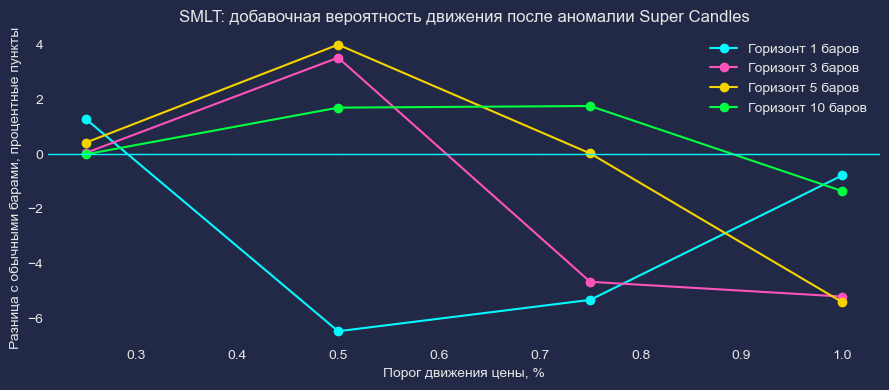

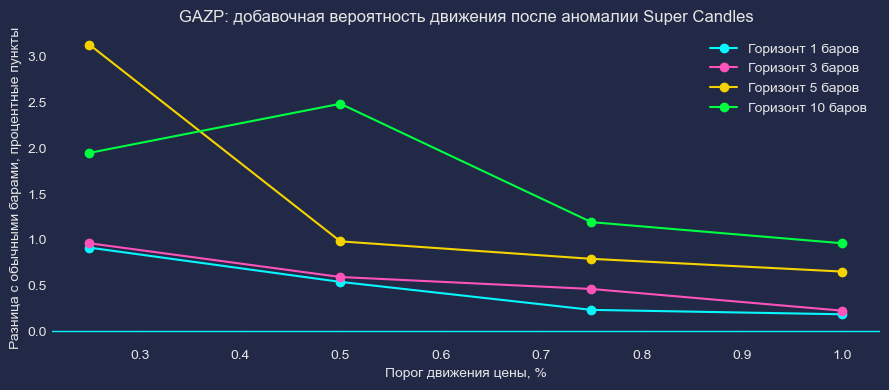

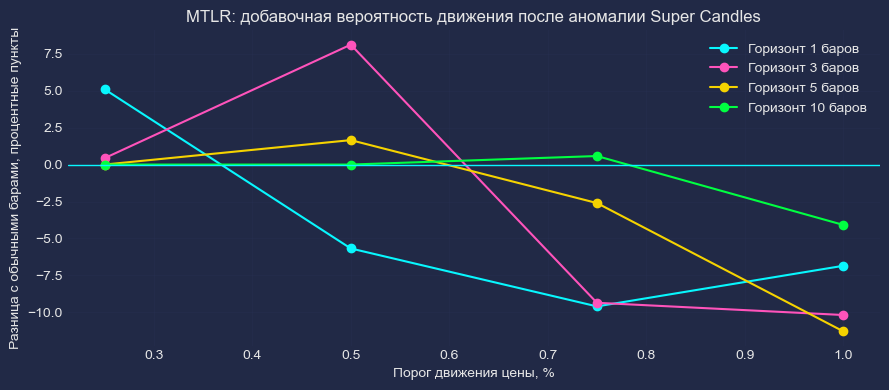

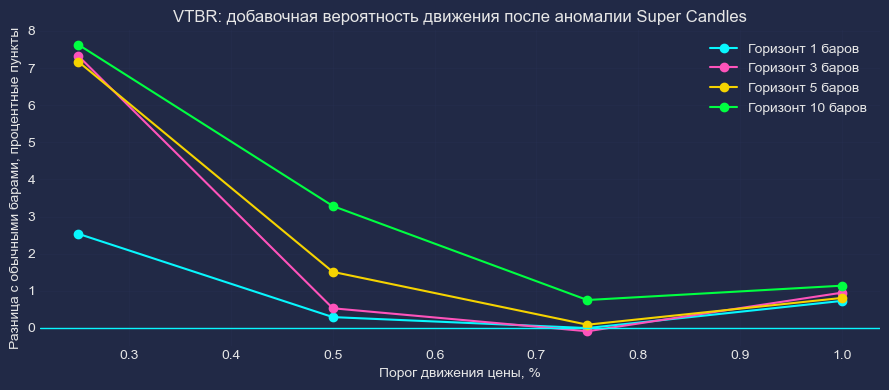

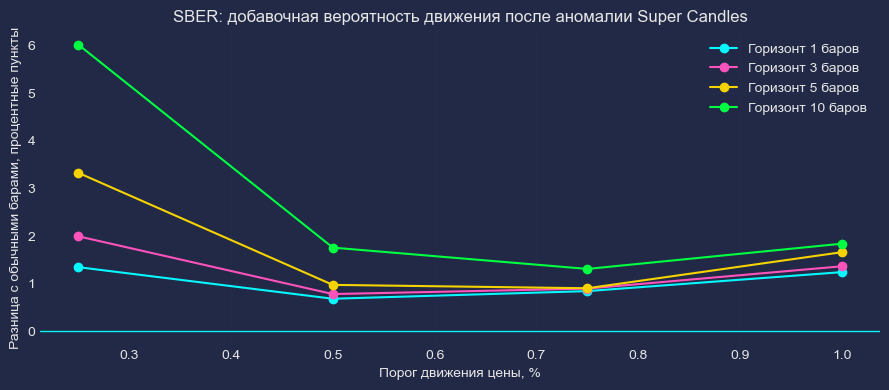

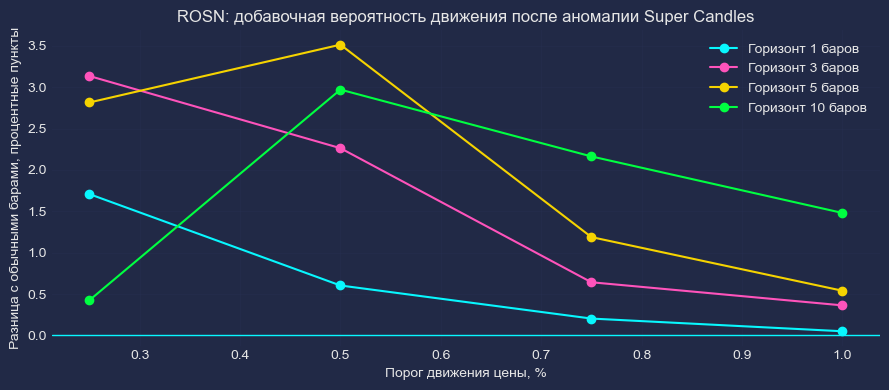

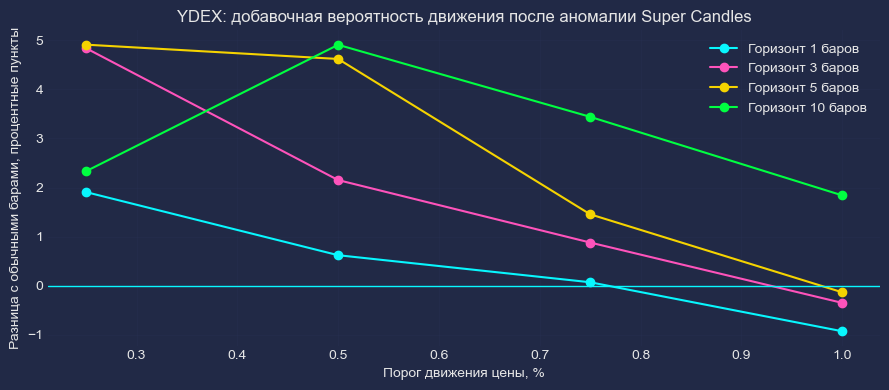

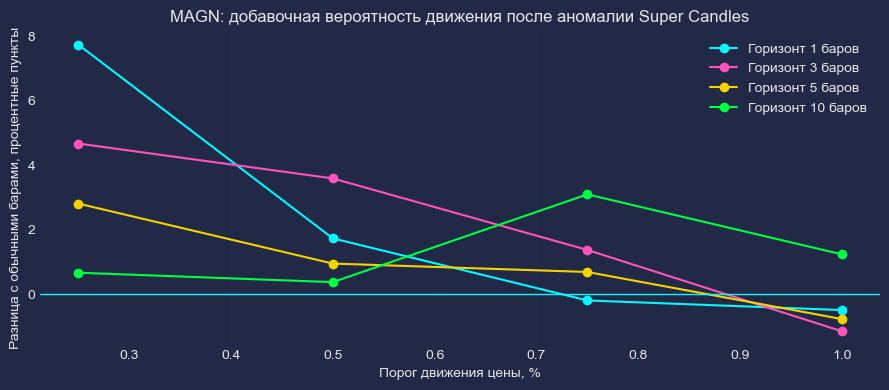

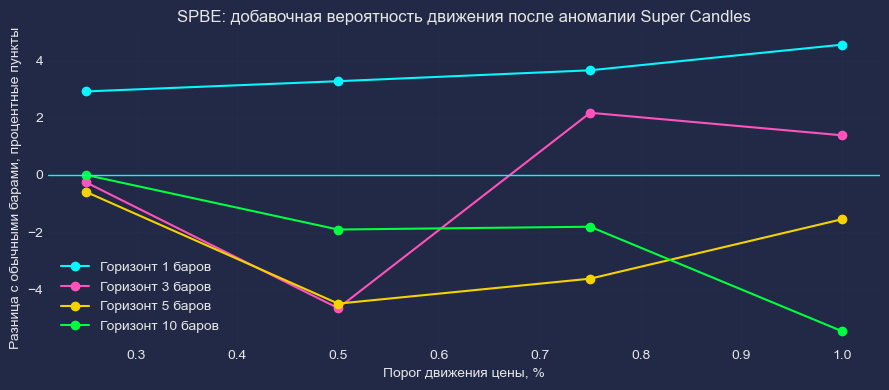

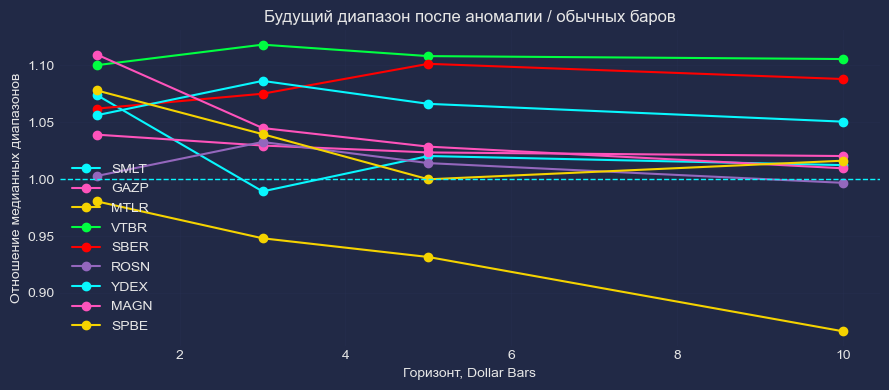

In [16]:
# Визуализация: вероятность движения, прирост относительно обычных баров и связь с будущим диапазоном.
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')
if not outcome_df.empty:
    plot_df = outcome_df[(outcome_df["группа"] == "ANY_GROUP") & (outcome_df["сторона"] == "любая_сторона")]
    if not plot_df.empty:
        for ticker in plot_df["тикер"].unique():
            d = plot_df[plot_df["тикер"] == ticker]
            fig, ax = plt.subplots(figsize=(9,4))
            for h in sorted(d["горизонт_баров"].dropna().unique()):
                z = d[d["горизонт_баров"] == h].groupby("порог_движения_pct")["прирост_вероятности_п.п."].mean()
                ax.plot(z.index, z.values, marker="o", label=f"Горизонт {int(h)} баров")
            ax.axhline(0, linewidth=1)
            ax.set_title(f"{ticker}: добавочная вероятность движения после аномалии Super Candles")
            ax.set_xlabel("Порог движения цены, %"); ax.set_ylabel("Разница с обычными барами, процентные пункты")
            ax.legend(); ax.grid(True, alpha=.25); plt.tight_layout(); plt.show()
if not regime_df.empty:
    d = regime_df[regime_df["группа"] == "ANY_GROUP"]
    if not d.empty:
        fig, ax = plt.subplots(figsize=(9,4))
        for ticker in d["тикер"].unique():
            z = d[d["тикер"] == ticker].groupby("горизонт_баров")["отношение_диапазонов"].median()
            ax.plot(z.index, z.values, marker="o", label=ticker)
        ax.axhline(1, linewidth=1, linestyle="--")
        ax.set_title("Будущий диапазон после аномалии / обычных баров")
        ax.set_xlabel("Горизонт, Dollar Bars"); ax.set_ylabel("Отношение медианных диапазонов")
        ax.legend(); ax.grid(True, alpha=.25); plt.tight_layout(); plt.show()


## Как читать результат

CSV `SC_05_supercandles_predictive_regimes.csv` использует русские названия столбцов:

- `частота` — сколько аномалий возникает в день;
- `движение_после_аномалии` — вероятность движения вверх, вниз или в любую сторону и её разница с обычными барами;
- `режим_волатильности_и_направления` — меняется ли будущий диапазон и вероятность продолжения направления.

**Положительная разница не доказывает прибыльность.** Это только признак прогностической информации. Проверки используют ограниченный набор групп и контрольные бары, поэтому найденные эффекты нужно подтвердить на другом временном отрезке и с реалистичным исполнением.

Если запуск снова идёт необычно долго, файл уже обновляется после каждого тикера. В начале каждой итерации печатается название тикера. Время загрузки исходных AlgoPack-данных и построения 474 признаков отдельно от времени данного исследования; если основное время тратится там, следующий шаг — кэшировать готовые `bars`, `scores` и не перестраивать их при каждом эксперименте.